# K-Nearest Neighbors (KNN): a hands-on tutorial

This notebook teaches KNN from the ground up. By the end you will have **built KNN yourself from scratch**, checked it against scikit-learn's version, and learned every practical decision that comes with using it: choosing `k`, scaling features, weighting votes, picking a distance metric, using it for regression, and knowing what it costs and where it breaks.

It is the foundation for the two experiment notebooks in this folder (`01_knn_high_dim.ipynb`, `02_dbscan_high_dim.ipynb`), which study how KNN and DBSCAN fail in high dimensions.

## Sections

| # | Section | What you'll learn |
|---|---|---|
| 0 | Setup | Libraries used throughout |
| 1 | The idea | KNN in one picture, no code beyond a plot |
| 2 | Measuring distance | Euclidean and Manhattan distance, by hand and vectorized |
| 3 | KNN from scratch | Find neighbors, vote, predict: about 10 lines of NumPy |
| 4 | A real train/test workflow | Splitting data, measuring accuracy, matching scikit-learn |
| 5 | Decision boundaries | What `k` does to the shape of the model |
| 6 | Choosing `k` | Overfitting vs underfitting, and cross-validation |
| 7 | Feature scaling | Why KNN breaks without it, and how to fix it properly |
| 8 | Weighted voting | Letting closer neighbors count more |
| 9 | KNN for regression | Predicting numbers instead of classes |
| 10 | Speed and cost | Why KNN is fast to train but slow to predict |
| 11 | Where KNN struggles | Irrelevant features: a preview of the high-dimension notebook |
| 12 | Summary | Cheat sheet, checklist, exercises |

## How to use this notebook

- **Run the cells in order**, top to bottom. Later sections reuse names defined earlier.
- Each section opens with an **objective** and the concepts you need, then alternates short explanations with code.
- **Every line of code is commented.** Read the comments, then change things and re-run. Most sections end with a **"Try it"** list of small experiments.

## 0. Setup

**Objective:** Import the libraries used throughout the tutorial.

In [1]:
import numpy as np                                   # arrays and math: every dataset here is a NumPy array
import matplotlib.pyplot as plt                      # plotting
from collections import Counter                      # counts items in a list; used to show votes in a readable way

from sklearn.datasets import make_moons, load_wine   # a synthetic 2-D dataset and a small real dataset
from sklearn.model_selection import train_test_split, cross_val_score   # splitting data and cross-validation
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor # scikit-learn's KNN for classes and for numbers
from sklearn.preprocessing import StandardScaler     # rescales each feature to mean 0, standard deviation 1
from sklearn.pipeline import make_pipeline           # chains steps (e.g. scaling, then KNN) into one model

np.set_printoptions(precision=3, suppress=True)      # print arrays with 3 decimals and no scientific notation

## 1. The idea

**Objective:** Understand what KNN does before writing any algorithm.

**The whole algorithm in one sentence:** to classify a new point, find the `k` labeled points closest to it and let them **vote**; the majority label wins.

**Key concepts:**
- **Training data:** points whose labels we already know. In KNN, the training data *is* the model. Nothing is "learned" or compressed; every point is kept and consulted at prediction time. That's why KNN is called a **lazy learner** (it postpones all work until prediction) and an **instance-based** method (it reasons directly from stored examples).
- **Non-parametric:** KNN has no fixed set of weights or coefficients. The more data you give it, the more detailed the model becomes.
- **`k`:** the number of neighbors that vote. It's the main setting (hyperparameter) you choose.
- **The assumption:** *points close to each other tend to share a label.* KNN works exactly as well as this assumption holds for your data and your definition of "close".

Let's look at a toy example with six labeled points and one new point.

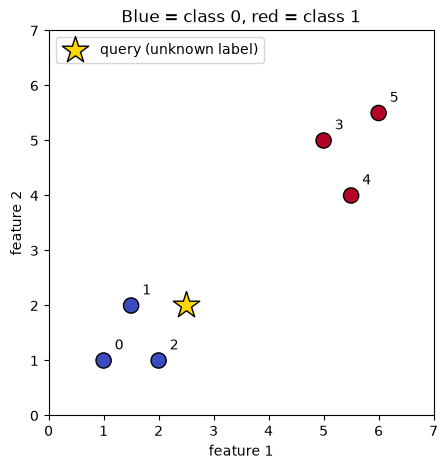

In [2]:
# Six training points. Each row is one point; the two columns are its two features (x and y coordinates).
X_toy = np.array([
    [1.0, 1.0],   # point 0
    [1.5, 2.0],   # point 1
    [2.0, 1.0],   # point 2
    [5.0, 5.0],   # point 3
    [5.5, 4.0],   # point 4
    [6.0, 5.5],   # point 5
])
y_toy = np.array([0, 0, 0, 1, 1, 1])   # labels: points 0-2 are class 0, points 3-5 are class 1
query = np.array([2.5, 2.0])           # a new point with no label: this is what we want to classify

fig, ax = plt.subplots(figsize=(5, 5))                              # one empty plot, 5x5 inches
ax.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="coolwarm",     # plot each training point at (x, y), colored by its label
           s=120, edgecolor="k")                                    # s = marker size; black outline
for i, (x, y) in enumerate(X_toy):                                  # loop over the points to label each one with its index
    ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(8, 8))   # write the index slightly up and to the right
ax.scatter(*query, marker="*", s=400, c="gold", edgecolor="k", label="query (unknown label)")  # the new point as a star
ax.set(xlim=(0, 7), ylim=(0, 7), xlabel="feature 1", ylabel="feature 2",
       title="Blue = class 0, red = class 1", aspect="equal")       # axis ranges, labels, title, equal x/y scaling
ax.legend(loc="upper left")                                         # show the legend for the star
plt.show()                                                          # render the figure

Before reading on, decide for yourself: **which class should the star get?**

You probably said blue, because the star sits among the blue points. That instinct ("look at what's nearby") is exactly KNN. The next two sections turn it into code: first we define "nearby" precisely (distance), then we find the nearest points and vote.

## 2. Measuring distance

**Objective:** Learn how "closeness" is measured, compute it by hand, then compute it for many points at once.

**Key concepts:**
- A point with `d` features is a vector $x = (x_1, x_2, \dots, x_d)$.
- **Euclidean distance** (straight-line, "as the crow flies"), the default in KNN:
  $$\text{dist}(a, b) = \sqrt{\sum_{j=1}^{d} (a_j - b_j)^2}$$
  This is Pythagoras' theorem extended to `d` dimensions.
- **Manhattan distance** (city-block: you can only move along the axes):
  $$\text{dist}(a, b) = \sum_{j=1}^{d} |a_j - b_j|$$
- Both are special cases of the **Minkowski distance** with parameter `p`: $\left(\sum_j |a_j-b_j|^p\right)^{1/p}$. `p = 2` gives Euclidean, `p = 1` gives Manhattan. scikit-learn's KNN exposes exactly this `p` parameter.

**Important:** every feature contributes to the distance equally, *in whatever units it happens to be measured in*. Keep that in mind; Section 7 shows why it matters.

**Step 1:** Euclidean distance between two points, written out one step at a time.

In [3]:
def euclidean(a, b):
    diff = a - b               # coordinate-by-coordinate differences, e.g. [2.5-1.0, 2.0-1.0] = [1.5, 1.0]
    squared = diff ** 2        # square each difference: [2.25, 1.0]
    total = squared.sum()      # add them up: 3.25
    return np.sqrt(total)      # square root of the total: about 1.80

def manhattan(a, b):
    return np.abs(a - b).sum() # absolute differences, added up: |1.5| + |1.0| = 2.5

print("Euclidean distance from the query to point 0:", round(euclidean(query, X_toy[0]), 3))  # straight-line distance
print("Manhattan distance from the query to point 0:", round(manhattan(query, X_toy[0]), 3))  # city-block distance

Euclidean distance from the query to point 0: 1.803
Manhattan distance from the query to point 0: 2.5


**Step 2:** Distance from the query to *every* training point. First with a plain loop (easy to read), then with one vectorized NumPy line (what you'd actually use).

**Broadcasting:** `X_toy` has shape `(6, 2)` and `query` has shape `(2,)`. In `X_toy - query`, NumPy automatically subtracts `query` from **each row**, giving a `(6, 2)` array of difference vectors. `axis=1` then tells `np.linalg.norm` to compute one length per row.

In [4]:
# Version A: a Python loop, one point at a time
dists_loop = []                                  # empty list to collect the distances
for point in X_toy:                              # iterate over the rows of X_toy (one row = one point)
    dists_loop.append(euclidean(query, point))   # compute and store this point's distance to the query
dists_loop = np.array(dists_loop)                # turn the list into a NumPy array

# Version B: vectorized, all points at once
dists = np.linalg.norm(X_toy - query, axis=1)    # subtract query from every row, then take each row's length

print("loop:      ", dists_loop)                 # the two versions...
print("vectorized:", dists)                      # ...should print identical numbers
print("same result?", np.allclose(dists_loop, dists))   # allclose compares floats with a tiny tolerance

loop:       [1.803 1.    1.118 3.905 3.606 4.95 ]
vectorized: [1.803 1.    1.118 3.905 3.606 4.95 ]
same result? True


**Try it:**
- Compute Manhattan distances to every point in one line. (Hint: `np.abs(...)` and `.sum(axis=1)`.)
- Does the *ranking* of points (nearest to farthest) change between Euclidean and Manhattan here?

## 3. KNN from scratch

**Objective:** Implement the complete KNN classifier yourself, to see that there is nothing hidden inside it.

**The algorithm, for one new point `x`:**
1. Compute the distance from `x` to every training point.
2. Sort those distances and take the indices of the `k` smallest: these are the **k nearest neighbors**.
3. Look up the neighbors' labels.
4. Count the votes per class; predict the class with the most votes.

**Key concepts:**
- `np.argsort(a)` returns the **indices** that would sort `a` from smallest to largest, not the sorted values. That's exactly what we need: *which* points are closest.
- `np.bincount(labels)` counts how many times each integer 0, 1, 2, ... appears. With labels `[0, 1, 1]` it returns `[1, 2]`: one vote for class 0, two for class 1. (Labels must be non-negative integers.)
- `np.argmax(votes)` returns the position of the largest count, which is the winning class. If two classes tie, `argmax` returns the first one (the smaller label). Using an **odd `k`** with two classes avoids ties entirely.

First, the algorithm step by step on the toy example with `k = 3`, printing every intermediate result:

In [5]:
k = 3                                            # number of neighbors that get to vote

distances = np.linalg.norm(X_toy - query, axis=1)    # step 1: distance from the query to every training point
print("1) distances to each point:   ", distances)

order = np.argsort(distances)                    # step 2a: point indices ordered from nearest to farthest
print("2) points from nearest to far:", order)

nearest = order[:k]                              # step 2b: keep only the first k indices
print(f"   the {k} nearest points:     ", nearest)

nearest_labels = y_toy[nearest]                  # step 3: look up the label of each neighbor
print("3) their labels:              ", nearest_labels)

votes = np.bincount(nearest_labels, minlength=2) # step 4a: count votes per class (minlength=2 ensures a slot for both classes)
print("4) votes per class [0, 1]:    ", votes)

prediction = np.argmax(votes)                    # step 4b: the class with the most votes wins
print("=> predicted class:           ", prediction)

1) distances to each point:    [1.803 1.    1.118 3.905 3.606 4.95 ]
2) points from nearest to far: [1 2 0 4 3 5]
   the 3 nearest points:      [1 2 0]
3) their labels:               [0 0 0]
4) votes per class [0, 1]:     [3 0]
=> predicted class:            0


Now the same logic packaged as reusable functions: one for a single point, one that loops over many.

In [6]:
def knn_predict_one(X_train, y_train, x, k):
    distances = np.linalg.norm(X_train - x, axis=1)   # distance from x to every training point
    nearest = np.argsort(distances)[:k]               # indices of the k closest training points
    votes = np.bincount(y_train[nearest])             # count the neighbors' labels per class
    return np.argmax(votes)                           # return the class with the most votes

def knn_predict(X_train, y_train, X_new, k):
    return np.array([knn_predict_one(X_train, y_train, x, k)   # classify each new point independently...
                     for x in X_new])                          # ...and collect the predictions into an array

# Classify three new points on the toy data
X_new = np.array([[2.5, 2.0],    # our original query, near the blue group
                  [5.0, 4.5],    # inside the red group
                  [3.5, 3.5]])   # roughly halfway between the two groups
print("predictions with k=3:", knn_predict(X_toy, y_toy, X_new, k=3))

predictions with k=3: [0 1 1]


That's the entire algorithm. Note what's missing: there is **no training step**. "Fitting" KNN means storing `X_train` and `y_train`; all the work happens inside `knn_predict`.

**Class probabilities:** the vote counts also give a natural confidence score. If 4 of 5 neighbors are class 1, KNN estimates P(class 1) = 4/5 = 0.8. scikit-learn exposes this as `predict_proba` (used in Section 4).

**Try it:**
- What does the point `[3.5, 3.5]` get with `k = 1`? With `k = 5`? With `k = 6` (every point votes)?
- With `k = 6`, all six points vote three against three. Which class wins, and why? (Look back at how `argmax` breaks ties.)

## 4. A real train/test workflow

**Objective:** Use KNN the way it's used in practice: split data into training and test sets, measure accuracy honestly, and confirm that our from-scratch version matches scikit-learn's.

**Key concepts:**
- **Training set:** the labeled points KNN stores and searches.
- **Test set:** labeled points we *hide* from the model, then use to check its predictions. Accuracy on data the model has already seen is misleadingly high (with `k = 1`, each training point is its own nearest neighbor, so training accuracy is always 100%).
- **Accuracy:** the fraction of test points predicted correctly.
- **`stratify=y`** in `train_test_split` keeps the class proportions the same in both parts.

**The dataset:** "two moons", two interleaving half-circles with some noise. A straight line can't separate the classes, but "look at your neighbors" can.

training points: (280, 2) | test points: (120, 2)


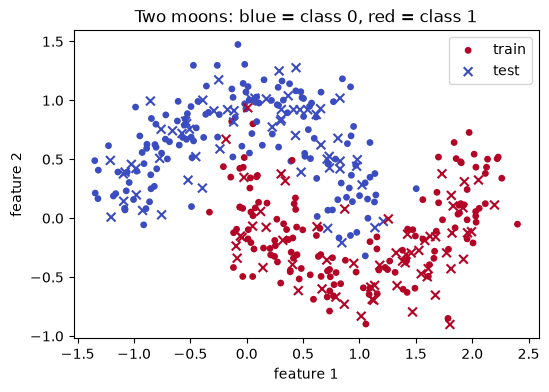

In [7]:
X, y = make_moons(n_samples=400, noise=0.2, random_state=0)   # 400 points with 2 features each, labels 0 or 1

X_train, X_test, y_train, y_test = train_test_split(   # split the data into two parts:
    X, y,                                              #   features and labels to split
    test_size=0.3,                                     #   30% for testing, 70% for training
    stratify=y,                                        #   keep the 50/50 class balance in both parts
    random_state=0,                                    #   fixed seed so the split is the same every run
)
print("training points:", X_train.shape, "| test points:", X_test.shape)   # (rows, columns) of each part

fig, ax = plt.subplots(figsize=(6, 4))                                     # one plot
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=15, label="train")          # training points: filled circles
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=40, marker="x", label="test")  # test points: crosses
ax.set(title="Two moons: blue = class 0, red = class 1", xlabel="feature 1", ylabel="feature 2")
ax.legend()                                                                # explain circles vs crosses
plt.show()

Predict the test set with **our** implementation and with **scikit-learn's**, and compare:

In [8]:
k = 5                                                            # 5 neighbors vote

ours = knn_predict(X_train, y_train, X_test, k=k)               # our from-scratch predictions for every test point
our_accuracy = (ours == y_test).mean()                           # True/False per point; the mean of booleans = fraction correct

sk_model = KNeighborsClassifier(n_neighbors=k)                   # scikit-learn's KNN with the same k (Euclidean distance by default)
sk_model.fit(X_train, y_train)                                   # "fit" = store the training data (plus build a search structure)
theirs = sk_model.predict(X_test)                                # scikit-learn's predictions
sk_accuracy = sk_model.score(X_test, y_test)                     # .score() computes accuracy directly

print(f"our accuracy:          {our_accuracy:.3f}")
print(f"scikit-learn accuracy: {sk_accuracy:.3f}")
print("identical predictions?", np.array_equal(ours, theirs))   # True means every single prediction matches

our accuracy:          0.942
scikit-learn accuracy: 0.942
identical predictions? True


Same predictions, so scikit-learn's KNN is doing exactly what we wrote. From here on we use scikit-learn for convenience and speed.

**Probabilities:** `predict_proba` returns the fraction of the `k` neighbors in each class. With `k = 5`, the only possible values are 0, 0.2, 0.4, 0.6, 0.8 and 1.

In [9]:
proba = sk_model.predict_proba(X_test[:5])        # class probabilities for the first 5 test points; one row per point
for p, pred, true in zip(proba, theirs[:5], y_test[:5]):   # walk through the 5 points together with their predictions
    print(f"P(class 0)={p[0]:.1f}  P(class 1)={p[1]:.1f}  -> predicted {pred}, true label {true}")

P(class 0)=1.0  P(class 1)=0.0  -> predicted 0, true label 0
P(class 0)=0.0  P(class 1)=1.0  -> predicted 1, true label 1
P(class 0)=1.0  P(class 1)=0.0  -> predicted 0, true label 0
P(class 0)=0.0  P(class 1)=1.0  -> predicted 1, true label 1
P(class 0)=1.0  P(class 1)=0.0  -> predicted 0, true label 0


## 5. Decision boundaries: what `k` does

**Objective:** See the model's behavior over the *whole* feature space, and how it changes with `k`.

**Key concepts:**
- **Decision boundary:** the line (in 2-D) where the prediction switches from one class to the other. To draw it, we classify a fine grid of points covering the plot and color each one by its predicted class.
- **Small `k`:** the prediction depends on very few points, so the boundary bends around individual (possibly noisy) points. Low **bias**, high **variance**: the model is flexible but jittery.
- **Large `k`:** many points vote, so the boundary is smooth, but it can wash out real structure. High bias, low variance. At the extreme, `k = n` (every point votes), the model predicts the majority class everywhere.

**A plotting helper.** `np.meshgrid` takes a list of x-values and a list of y-values and builds every (x, y) combination, i.e. a grid. We classify all grid points at once and draw the result as colored regions.

In [10]:
def plot_decision_boundary(model, X, y, ax, title=""):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5   # horizontal extent of the grid, with a 0.5 margin
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5   # vertical extent of the grid, with a 0.5 margin
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),      # 300 evenly spaced x-values...
                         np.linspace(y_min, y_max, 300))      # ...times 300 y-values = a 300x300 grid
    grid = np.c_[xx.ravel(), yy.ravel()]                      # flatten into a (90000, 2) array: one grid point per row
    Z = model.predict(grid).reshape(xx.shape)                 # predict every grid point, then reshape back to 300x300
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")       # fill each region with the color of its predicted class
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",        # draw the actual points on top...
               s=12, edgecolor="k", linewidth=0.3)            # ...small, with a thin black outline
    ax.set_title(title)                                       # panel title

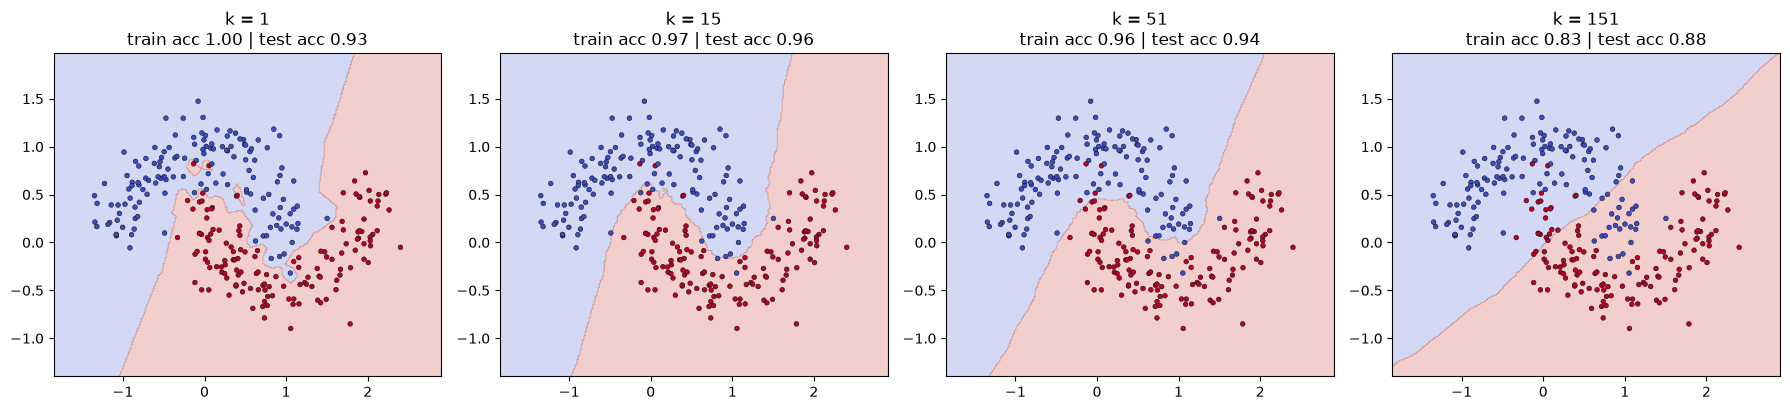

In [11]:
ks = [1, 15, 51, 151]                                              # the values of k to compare
fig, axes = plt.subplots(1, len(ks), figsize=(18, 4.2))           # one panel per k, side by side

for ax, k in zip(axes, ks):                                       # pair each panel with one k
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)    # create and fit a KNN with this k
    train_acc = model.score(X_train, y_train)                     # accuracy on the points it has stored
    test_acc = model.score(X_test, y_test)                        # accuracy on unseen points
    plot_decision_boundary(model, X_train, y_train, ax,           # draw its decision regions over the training data
                           title=f"k = {k}\ntrain acc {train_acc:.2f} | test acc {test_acc:.2f}")

plt.tight_layout()                                                # avoid overlapping titles and labels
plt.show()

**How to read it:**
- **`k = 1`:** the boundary wraps around every single training point, including noisy points that sit deep inside the other class. Training accuracy is a perfect 1.00 (every point is its own nearest neighbor), but test accuracy is lower. This is **overfitting**.
- **Moderate `k`:** smooth boundaries that follow the moon shapes.
- **Large `k`:** the boundary gets too simple and starts cutting through the moons. This is **underfitting**.

**Try it:** Rerun with `noise=0.1` and with `noise=0.4` in `make_moons` (Section 4). How does the best-looking `k` change?

## 6. Choosing `k`

**Objective:** Pick `k` systematically instead of by eye, *without* cheating by using the test set.

**Key concepts:**
- Plotting accuracy against `k` for both the training and the test set shows the overfitting/underfitting trade-off directly.
- **Never choose hyperparameters on the test set.** If you try 50 values of `k` and keep whichever scores best on the test set, that score is optimistic: you've tuned the model to those particular test points. The test set should be used **once**, at the very end.
- **Cross-validation (CV)** chooses `k` using only the training set. In **5-fold CV**, the training data is split into 5 equal parts ("folds"); the model is trained on 4 folds and evaluated on the 5th, rotating through all 5. The average of the 5 scores estimates how well that `k` generalizes.

First, the trade-off picture: training and test accuracy for every odd `k` from 1 to 199. (The training set has 280 points, so `k = 199` means most of the data votes on every prediction.)

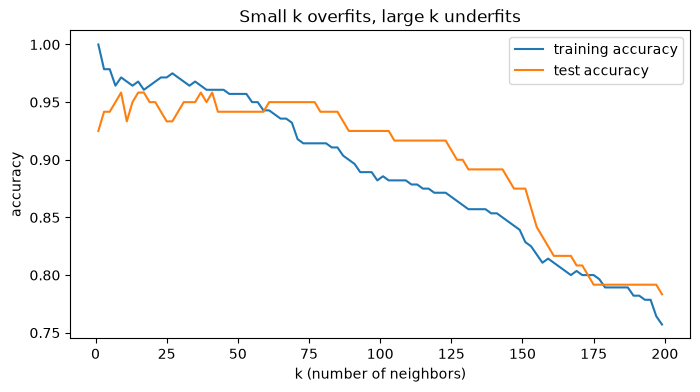

In [12]:
k_values = list(range(1, 200, 2))                     # odd k only (1, 3, 5, ..., 199): no voting ties with 2 classes
train_scores, test_scores = [], []                    # lists to collect accuracies

for k in k_values:                                    # try every k
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)   # fit KNN with this k
    train_scores.append(model.score(X_train, y_train))                  # accuracy on the stored training points
    test_scores.append(model.score(X_test, y_test))                     # accuracy on unseen test points

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, train_scores, label="training accuracy")   # starts at 1.0 for k=1, then drops
ax.plot(k_values, test_scores, label="test accuracy")        # the curve we actually care about
ax.set(xlabel="k (number of neighbors)", ylabel="accuracy",
       title="Small k overfits, large k underfits")
ax.legend()
plt.show()

Now the honest way: choose `k` with 5-fold cross-validation on the **training set only**, then evaluate once on the test set.

best k by 5-fold CV: 19 (mean CV accuracy 0.971)
test accuracy with k=19: 0.950


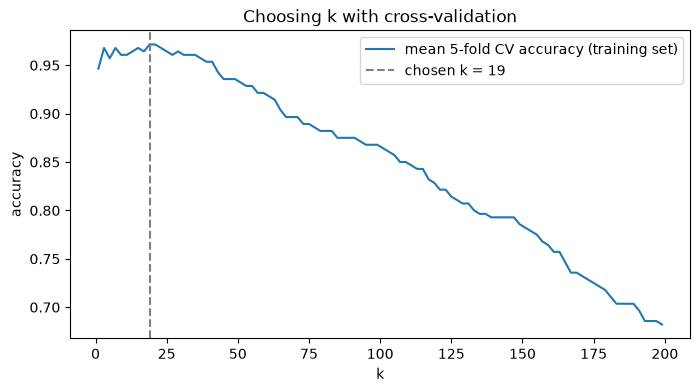

In [13]:
cv_means = []                                                  # mean CV accuracy for each k
for k in k_values:                                             # try every k
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k),   # a fresh, unfitted model with this k
                             X_train, y_train,                      # ONLY the training data is used here
                             cv=5)                                  # 5 folds -> 5 accuracy scores
    cv_means.append(scores.mean())                             # average the 5 scores into one number

best_k = k_values[int(np.argmax(cv_means))]                    # the k with the highest mean CV accuracy
print(f"best k by 5-fold CV: {best_k} (mean CV accuracy {max(cv_means):.3f})")

final_model = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)   # refit on the full training set with best_k
print(f"test accuracy with k={best_k}: {final_model.score(X_test, y_test):.3f}")  # the one-time, honest test score

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, cv_means, label="mean 5-fold CV accuracy (training set)")   # what we chose k from
ax.axvline(best_k, color="gray", ls="--", label=f"chosen k = {best_k}")       # mark the choice
ax.set(xlabel="k", ylabel="accuracy", title="Choosing k with cross-validation")
ax.legend()
plt.show()

**Rules of thumb for `k`:**
- Use an **odd** `k` for two-class problems to avoid tied votes.
- A common starting point is `k ≈ √n`, but always confirm with cross-validation.
- The CV curve is often flat near its peak. Any `k` in that flat region is fine; prefer a slightly larger one there, since it's more stable.

## 7. Feature scaling: the most common KNN mistake

**Objective:** See how features measured in different units distort distances, and fix it correctly.

**Key concepts:**
- Euclidean distance adds up $(a_j - b_j)^2$ over all features. A feature measured in the **thousands** produces squared differences around a million, while a feature measured in **tenths** contributes about 0.01. The large-unit feature effectively decides the distance by itself, and the other features are ignored.
- **Standardization** (`StandardScaler`) rescales each feature to mean 0 and standard deviation 1: $z = (x - \text{mean}) / \text{std}$. After that, every feature has the same typical size and the same say in the distance.
- **Do it inside a pipeline.** The scaler's mean and std must be computed from **training data only**; computing them on all the data leaks information from the test set. `make_pipeline(StandardScaler(), KNeighborsClassifier())` handles this automatically, including inside cross-validation.

**The dataset:** the classic Wine dataset: 178 wines from 3 grape cultivars, with 13 chemical measurements in very different units.

In [14]:
wine = load_wine()                       # load the dataset bundled with scikit-learn
X_wine, y_wine = wine.data, wine.target  # features: (178, 13) array; labels: 0, 1 or 2 (three cultivars)

print(f"{'feature':<30}{'min':>10}{'max':>10}")                  # table header
for name, col in zip(wine.feature_names, X_wine.T):             # X_wine.T: transpose, so we loop over columns (features)
    print(f"{name:<30}{col.min():>10.2f}{col.max():>10.2f}")    # each feature's smallest and largest value

feature                              min       max
alcohol                            11.03     14.83
malic_acid                          0.74      5.80
ash                                 1.36      3.23
alcalinity_of_ash                  10.60     30.00
magnesium                          70.00    162.00
total_phenols                       0.98      3.88
flavanoids                          0.34      5.08
nonflavanoid_phenols                0.13      0.66
proanthocyanins                     0.41      3.58
color_intensity                     1.28     13.00
hue                                 0.48      1.71
od280/od315_of_diluted_wines        1.27      4.00
proline                           278.00   1680.00


Look at the ranges: `proline` goes up to about 1680, while `hue` stays between roughly 0.5 and 1.7. Let's measure how much each feature contributes to the squared distance between two wines:

In [15]:
a, b = X_wine[0], X_wine[100]                    # two wines from the dataset (from different cultivars)
contrib = (a - b) ** 2                           # each feature's contribution to the squared Euclidean distance
share = contrib / contrib.sum()                  # as a fraction of the total

top = np.argsort(share)[::-1][:4]                # indices of the 4 biggest contributors ([::-1] reverses to descending)
for j in top:                                    # print them
    print(f"{wine.feature_names[j]:<30} {share[j]:7.1%} of the squared distance")

proline                          99.3% of the squared distance
magnesium                         0.7% of the squared distance
color_intensity                   0.0% of the squared distance
alcohol                           0.0% of the squared distance


One feature contributes almost the entire distance. Now compare KNN without and with scaling, using 5-fold cross-validation:

In [16]:
raw_knn = KNeighborsClassifier(n_neighbors=5)                          # KNN on the raw, unscaled features
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))   # scale first, then KNN, as one model

raw_cv = cross_val_score(raw_knn, X_wine, y_wine, cv=5)               # 5 accuracy scores without scaling
scaled_cv = cross_val_score(scaled_knn, X_wine, y_wine, cv=5)         # 5 accuracy scores with scaling
# In each CV fold, the pipeline fits the scaler on that fold's training part only: no leakage.

print(f"without scaling: {raw_cv.mean():.3f} mean CV accuracy")
print(f"with scaling:    {scaled_cv.mean():.3f} mean CV accuracy")

without scaling: 0.691 mean CV accuracy
with scaling:    0.949 mean CV accuracy


Same algorithm, same `k`, same data, very different accuracy. **Always scale your features before KNN**, unless they're already in comparable units (pixel intensities, for example).

**Other scalers:** `MinMaxScaler` maps each feature to [0, 1]; `RobustScaler` uses the median and interquartile range, so it's less sensitive to outliers. `StandardScaler` is a good default.

## 8. Weighted voting

**Objective:** Learn the `weights` option, which lets closer neighbors count more.

**Key concepts:**
- **`weights="uniform"`** (the default): each of the `k` neighbors gets one vote, no matter how far away it is.
- **`weights="distance"`:** each neighbor's vote is worth $1 / \text{distance}$, so a neighbor twice as close counts twice as much. This makes the prediction less sensitive to the exact choice of `k`, and lets a few very close neighbors outvote several distant ones.

A small 1-D example where the two options disagree:

In [17]:
X_w = np.array([[0.5], [0.6], [2.0], [2.1], [2.2]])   # five training points on a line (one feature each)
y_w = np.array([0, 0, 1, 1, 1])                       # two close points of class 0, three farther points of class 1
q = np.array([[0.0]])                                 # the query sits at 0, right next to the class-0 points

for w in ["uniform", "distance"]:                                            # try both weighting schemes
    model = KNeighborsClassifier(n_neighbors=5, weights=w).fit(X_w, y_w)    # all 5 points vote
    print(f"weights={w!r:<11} -> predicts class {model.predict(q)[0]}, "    # the predicted class...
          f"P = {model.predict_proba(q)[0].round(2)}")                       # ...and the vote shares [P(0), P(1)]

d = np.abs(X_w[:, 0] - q[0, 0])                       # distance from the query to each point
print("\ndistance-weighted vote totals:")
print("  class 0:", round((1 / d[y_w == 0]).sum(), 2))   # 1/0.5 + 1/0.6
print("  class 1:", round((1 / d[y_w == 1]).sum(), 2))   # 1/2.0 + 1/2.1 + 1/2.2

weights='uniform'   -> predicts class 1, P = [0.4 0.6]
weights='distance'  -> predicts class 0, P = [0.72 0.28]

distance-weighted vote totals:
  class 0: 3.67
  class 1: 1.43


With uniform weights, class 1 wins 3 votes to 2. With distance weights, the two very close class-0 points outweigh the three distant ones.

**When to use which:** try both in cross-validation. `"distance"` often helps when classes have uneven density or when you're unsure about `k`. One edge case: if a query is *exactly* on a training point (distance 0), scikit-learn gives that point all the weight.

## 9. KNN for regression

**Objective:** Use the same idea to predict a **number** instead of a class.

**Key concept:** instead of a majority vote, take the **average** of the neighbors' target values (or a distance-weighted average with `weights="distance"`). Everything else (distance, `k`, scaling) works the same way. In scikit-learn this is `KNeighborsRegressor`.

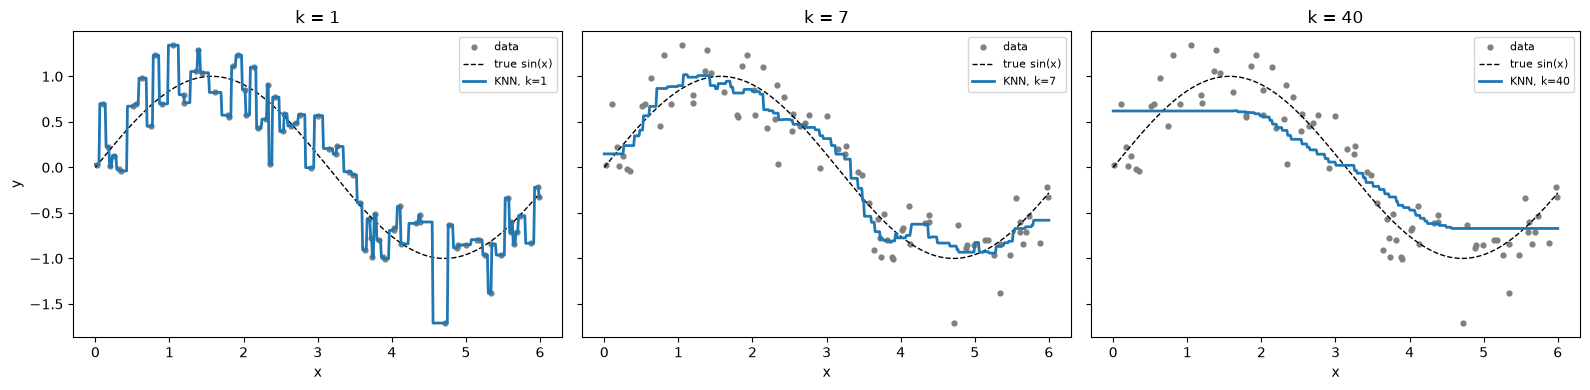

In [18]:
rng = np.random.default_rng(0)                            # random number generator with a fixed seed
x_reg = np.sort(rng.uniform(0, 6, size=80))               # 80 x-values between 0 and 6, sorted for neat plotting
y_reg = np.sin(x_reg) + rng.normal(0, 0.3, size=80)       # target: a sine wave plus random noise
X_reg = x_reg.reshape(-1, 1)                              # scikit-learn expects a 2-D array: 80 rows, 1 feature

x_plot = np.linspace(0, 6, 500).reshape(-1, 1)            # 500 evenly spaced inputs at which to draw each model's prediction

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)   # three panels sharing one y-axis
for ax, k in zip(axes, [1, 7, 40]):                             # three values of k
    model = KNeighborsRegressor(n_neighbors=k).fit(X_reg, y_reg)   # fit the regressor
    ax.scatter(x_reg, y_reg, s=12, color="gray", label="data")       # the noisy training points
    ax.plot(x_plot, np.sin(x_plot), "k--", lw=1, label="true sin(x)")   # the function that generated the data
    ax.plot(x_plot, model.predict(x_plot), lw=2, label=f"KNN, k={k}")  # the model's prediction everywhere
    ax.set(title=f"k = {k}", xlabel="x")
    ax.legend(fontsize=8)
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

The same trade-off as in classification: `k = 1` chases every noisy point (overfitting), a moderate `k` follows the sine wave, and a large `k` flattens it (underfitting). The predictions look like **steps**, because the prediction only changes when the set of nearest neighbors changes.

## 10. Speed and cost

**Objective:** Understand KNN's computational profile, which is unusual among models.

**Key concepts:**
- **Training is almost free:** `fit` only stores the data (and optionally builds a search index).
- **Prediction is expensive:** done naively, each prediction computes the distance to **all** `n` training points in `d` dimensions, which costs about `n × d` operations per query. A model trained on millions of points is slow to query, and the whole training set must stay in memory.
- **Search structures** (KD-tree, ball tree) organize the training points so that most of them can be skipped during a search. scikit-learn picks one automatically (`algorithm="auto"`), or you can choose `"brute"`, `"kd_tree"` or `"ball_tree"`.
- These structures work well in low dimensions, but lose their advantage as `d` grows: in high dimensions they end up checking nearly every point anyway. That's another face of the curse of dimensionality, and the cell below measures it.

In [19]:
import time                                               # for measuring elapsed time

rng = np.random.default_rng(0)                            # fixed seed
n_train, n_query = 20_000, 2_000                          # training points to search, and queries to answer

for d in [2, 10, 50]:                                     # three dimensionalities
    X_big = rng.standard_normal((n_train, d))             # random training points
    y_big = (X_big[:, 0] > 0).astype(int)                 # a simple label (sign of the first feature); labels don't affect speed
    Q = rng.standard_normal((n_query, d))                 # random query points
    timings = []                                          # one timing per search algorithm
    for algo in ["brute", "kd_tree"]:                     # brute = compare with every point; kd_tree = use a tree index
        model = KNeighborsClassifier(n_neighbors=5, algorithm=algo).fit(X_big, y_big)   # build the model (and tree)
        start = time.perf_counter()                       # start the clock
        model.predict(Q)                                  # answer all queries
        timings.append(time.perf_counter() - start)       # stop the clock, store the elapsed seconds
    speedup = timings[0] / timings[1]                     # how many times faster the tree is than brute force
    verdict = "tree helps" if speedup > 1 else "tree HURTS"   # above 1 = tree faster; below 1 = tree slower
    print(f"d = {d:>2}: brute {timings[0]:.3f}s | kd_tree {timings[1]:.3f}s "
          f"| tree speedup {speedup:5.2f}x ({verdict})")

d =  2: brute 0.013s | kd_tree 0.002s | tree speedup  5.52x (tree helps)


d = 10: brute 0.013s | kd_tree 0.104s | tree speedup  0.13x (tree HURTS)


d = 50: brute 0.017s | kd_tree 0.839s | tree speedup  0.02x (tree HURTS)


In 2-D, the tree is several times faster than brute force. As `d` grows it loses that advantage, and typically ends up *slower* than brute force, because it does the work of navigating the tree and still has to check most of the points. (Exact times depend on your machine; the trend is what matters.)

**In practice:** for large, high-dimensional datasets (e.g. search over embeddings), people use **approximate nearest-neighbor** libraries such as FAISS, Annoy or HNSW, which trade a little accuracy for a large speedup.

## 11. Where KNN struggles: irrelevant features

**Objective:** See KNN's biggest weakness, and set up the question explored in `01_knn_high_dim.ipynb`.

**Key concept:** KNN gives **every feature an equal say** in the distance. It has no way to learn that some features matter and others don't. Features that carry no information about the label still add their random differences to every distance, and those differences can drown out the features that do matter.

Below, we take the moons data (2 useful features) and add more and more columns of pure random noise.

In [20]:
rng = np.random.default_rng(0)                         # fixed seed for the noise
X_m, y_m = make_moons(n_samples=600, noise=0.2, random_state=0)   # 2 informative features
X_m = StandardScaler().fit_transform(X_m)              # scale the informative features to std 1, like the noise below

for n_noise in [0, 2, 10, 50, 200]:                    # how many useless features to add
    noise = rng.standard_normal((len(X_m), n_noise))   # n_noise columns of random numbers, unrelated to the labels
    X_aug = np.hstack([X_m, noise])                    # glue them onto the right of the real features
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=15), X_aug, y_m, cv=5).mean()   # mean 5-fold CV accuracy
    print(f"{n_noise:>3} noise features (total {X_aug.shape[1]:>3}): accuracy {acc:.3f}")

  0 noise features (total   2): accuracy 0.968
  2 noise features (total   4): accuracy 0.927
 10 noise features (total  12): accuracy 0.862
 50 noise features (total  52): accuracy 0.770
200 noise features (total 202): accuracy 0.655


Accuracy falls toward 0.5 (coin-flip guessing) as useless features pile up, even though the two useful features are still there, untouched.

**Why?** That's what the next notebook investigates in depth: how distances behave as dimensions grow (they "concentrate"), how neighborhoods lose their purity, why some points become "hubs", and whether it's the number of dimensions or the noise in them that does the damage.

**Practical defenses:** feature selection (keep only informative features), dimensionality reduction (PCA, UMAP) before KNN, metric learning (learning a distance that weighs features by usefulness), or using a model that learns feature weights.

## 12. Summary

### KNN in five lines
1. Store the training data. That's the whole "training".
2. For a new point, compute its distance to every training point.
3. Take the `k` nearest.
4. Classification: majority vote (optionally distance-weighted). Regression: average.
5. Everything depends on the distance being meaningful.

### Hyperparameters (scikit-learn)

| Parameter | What it controls | Typical choice |
|---|---|---|
| `n_neighbors` | `k`: how many neighbors vote | Choose with cross-validation; odd for 2 classes |
| `weights` | `"uniform"` or `"distance"` (1/distance) | Try both in CV |
| `metric`, `p` | The distance: `p=2` Euclidean, `p=1` Manhattan | Euclidean by default |
| `algorithm` | Search method: `"auto"`, `"brute"`, `"kd_tree"`, `"ball_tree"` | `"auto"` |

### Strengths and weaknesses

| Strengths | Weaknesses |
|---|---|
| Simple and easy to explain | Slow predictions on big datasets; must keep all data in memory |
| No training time | Requires feature scaling |
| Handles any boundary shape, any number of classes | Hurt badly by irrelevant features and high dimensions |
| Naturally gives probabilities (vote shares) | Sensitive to the choice of `k` and of the distance metric |

### Checklist before using KNN
- [ ] Features are **scaled** (inside a pipeline, to avoid leakage)
- [ ] `k` (and `weights`) are chosen by **cross-validation**, not on the test set
- [ ] Irrelevant features are removed, or dimensionality is reduced
- [ ] The dataset is small enough to search at prediction time, or an approximate method is used

### Exercises
1. Extend `knn_predict_one` to support `weights="distance"`, and check your predictions against scikit-learn on the moons data.
2. Add a `p` argument to your implementation to support Manhattan distance. Does it change the moons accuracy?
3. On the Wine data, use cross-validation to choose `k` *inside* the scaling pipeline. (Hint: `GridSearchCV` with the parameter name `kneighborsclassifier__n_neighbors`.)
4. Implement `knn_regress_one` (average instead of vote) and reproduce the plot from Section 9.
5. In Section 11, replace KNN with `LogisticRegression`. Does it degrade the same way as noise features are added? Why might it not?

**Next:** `01_knn_high_dim.ipynb`, which takes Section 11's question apart, one effect at a time.